# Datos y demanda observada

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import datos

plt.style.use("../config/graficos.mplstyle")
TABLAS = Path("../results/datos/tablas")
FIGURAS = Path("../results/datos/figuras")
TABLAS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

GRIS_OSCURO = "#333333"
GRIS_MEDIO = "#888888"


def formato_es(df, decimales=0, porcentajes=(), dec_pct=1):
    """Presenta una tabla con separador de miles y coma decimal."""
    formatos = {c: f"{{:.{dec_pct}%}}" for c in porcentajes}
    estilo = df.style.format(precision=decimales, thousands=".", decimal=",", na_rep="—")
    for columna, patron in formatos.items():
        estilo = estilo.format(
            lambda x, p=patron: "—" if pd.isna(x) else p.format(x).replace(".", ",").replace("%", " %"),
            subset=[columna],
        )
    return estilo


def guardar_tabla(tabla, nombre):
    tabla.to_csv(TABLAS / f"{nombre}.csv", index=False)


def guardar_figura(fig, nombre):
    for extension in ["png", "svg"]:
        fig.savefig(
            FIGURAS / f"{nombre}.{extension}",
            dpi=300,
            bbox_inches="tight",
            facecolor="white",
        )


## Carga y comprobaciones

In [2]:
dd = datos.cargar_datos()
comprobaciones = datos.comprobar_datos(dd)
guardar_tabla(comprobaciones, "comprobaciones_datos")
print(f"Comprobaciones correctas: {comprobaciones['correcto'].sum()} de {len(comprobaciones)}")
comprobaciones

Comprobaciones correctas: 25 de 25


,comprobacion,correcto,detalle
0,Claves únicas en ventas,True,0 duplicados
1,Meses completos en ventas,True,"t 25-144, 21 series"
2,Claves únicas en stock,True,0 duplicados
3,Meses completos en stock,True,"t 97-144, 7 series"
4,Claves únicas en mercado,True,0 duplicados
5,Meses completos en mercado,True,"t 1-144, 21 series"
6,Claves únicas en economia,True,0 duplicados
7,Meses completos en economia,True,"t 1-144, 1 series"
8,Segmentos y canales esperados,True,"7 segmentos, 3 canales"
9,Calendario A013 con 12 meses (t 145-156),True,12 meses


## Balance y serie mensual

In [3]:
balance = datos.balance_stock(dd).dropna(subset=["residuo"])
resumen_balance = balance.groupby("segmento").agg(
    meses=("residuo", "size"),
    meses_con_residuo=("residuo", lambda x: (x != 0).sum()),
    residuo_max_abs=("residuo", lambda x: x.abs().max()),
    residuo_acumulado=("residuo", "sum"),
    residuo_medio_sin_automatriculacion=("residuo_sin_automatriculacion", "mean"),
).reindex(datos.SEGMENTOS)
guardar_tabla(resumen_balance.reset_index(), "balance_stock_segmento")
display(formato_es(resumen_balance, decimales=1))
residuos_relevantes = balance.loc[
    balance["residuo"].abs() > 5,
    ["segmento", "periodo", "stock_anterior", "wholesale", "unidades", "stock_total", "residuo"],
]
guardar_tabla(residuos_relevantes, "balance_stock_residuos_mayores_5")
residuos_relevantes

,meses,meses_con_residuo,residuo_max_abs,residuo_acumulado,residuo_medio_sin_automatriculacion
segmento,,,,,
B,47,8,"1,0","0,0","-17,2"
C,47,30,"2,0","0,0","-36,7"
MD,47,8,"8,0","0,0","-14,6"
SSUV,47,21,"51,0","-2,0","-40,1"
CSUV,47,0,"0,0","0,0","-5,2"
MSUV,47,31,"5,0","0,0","-42,6"
S,47,4,"1,0","0,0","-7,2"


,segmento,periodo,stock_anterior,wholesale,unidades,stock_total,residuo
158,MD,A0100301,331.0,119.0,128,314,-8.0
159,MD,A0100401,314.0,121.0,125,318,8.0
293,SSUV,A0090601,781.0,289.0,493,628,51.0
294,SSUV,A0090701,628.0,254.0,354,478,-50.0


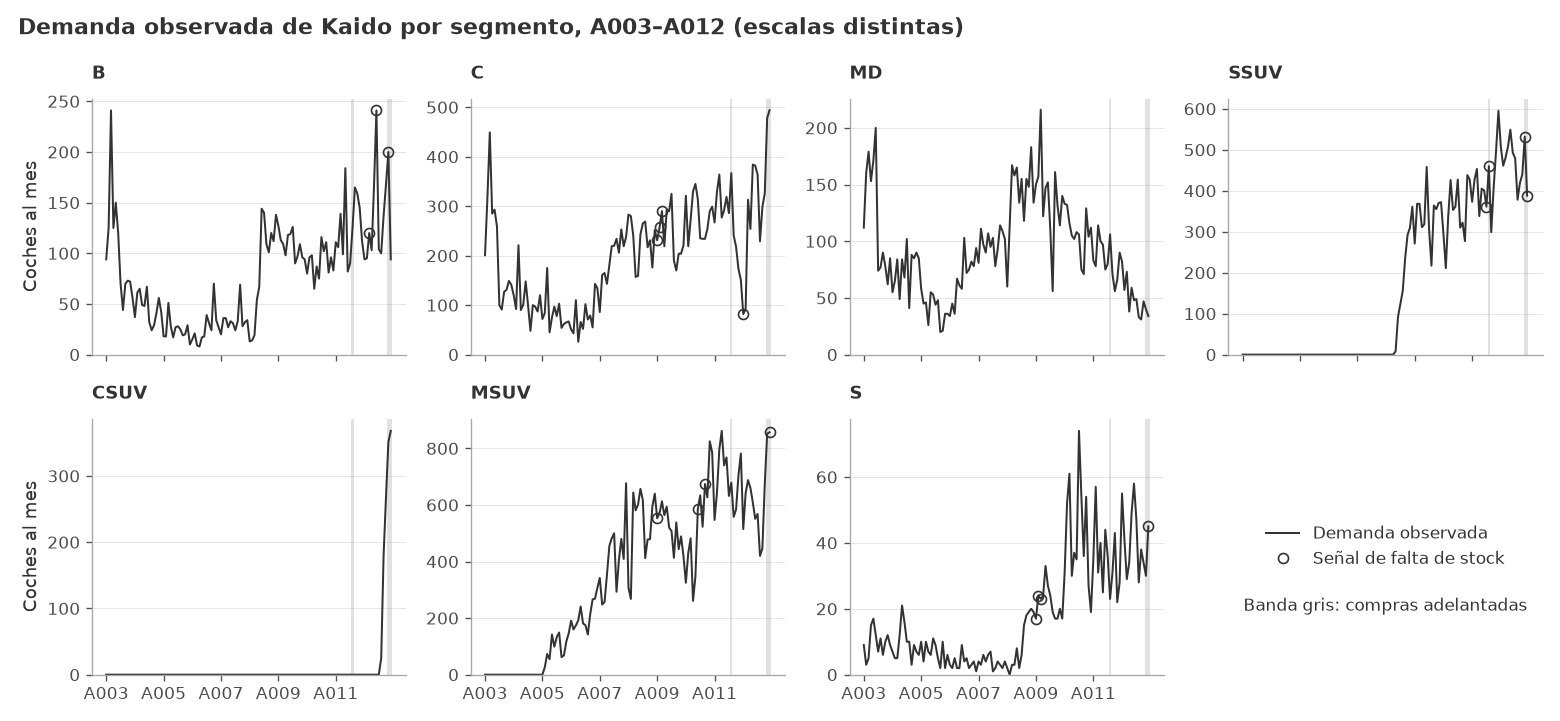

In [4]:
serie = datos.serie_mensual_segmento(dd)
guardar_tabla(serie.drop(columns="fecha"), "serie_mensual_segmento_a003_a012")

fig, ejes = plt.subplots(2, 4, figsize=(13, 6), sharex=True)
for eje, segmento in zip(ejes.flat, datos.SEGMENTOS):
    s = serie[serie["segmento"] == segmento]
    eje.plot(s["t"], s["demanda_observada"], color=GRIS_OSCURO, lw=1.2,
             label="Demanda observada")
    for t in s.loc[s["adelanto_compras"] == 1, "t"]:
        eje.axvspan(t - 0.5, t + 0.5, color=GRIS_MEDIO, alpha=0.25, lw=0)
    falta = s[s["senal_falta_stock"] == 1]
    eje.plot(falta["t"], falta["demanda_observada"], "o", mfc="none",
             mec=GRIS_OSCURO, ms=6, label="Señal de falta de stock")
    eje.set_title(segmento, fontsize=11)
    eje.set_ylim(bottom=0)
ejes.flat[-1].axis("off")
ejes.flat[-1].legend(*ejes.flat[0].get_legend_handles_labels(), loc="center")
ejes.flat[-1].text(0.5, 0.25, "Banda gris: compras adelantadas", ha="center",
                   transform=ejes.flat[-1].transAxes, fontsize=10)
inicios = list(range(25, 145, 24))
for eje in ejes[1]:
    eje.set_xticks(inicios, [f"A{(t - 1) // 12 + 1:03d}" for t in inicios])
for eje in ejes[:, 0]:
    eje.set_ylabel("Coches al mes")
fig.suptitle("Demanda observada de Kaido por segmento, A003–A012 "
             "(escalas distintas)", x=0.01, ha="left", fontweight="bold")
guardar_figura(fig, "demanda_observada_segmento_a003_a012")
plt.show()

## Señales y diagnóstico de A012

In [5]:
falta = serie[serie["senal_falta_stock"] == 1].assign(
    stock_libre_meses=lambda d: d["s_sin_cliente"] / d["matriculaciones"]
)[["segmento", "periodo", "matriculaciones", "stock_total", "s_sin_cliente",
   "stock_libre_meses", "adelanto_compras"]]
guardar_tabla(falta, "senales_falta_stock")
con_stock = serie["stock_total"].notna().sum()
print(f"Meses con señal: {len(falta)} de {con_stock} segmento-mes con datos de stock")
formato_es(falta.reset_index(drop=True), decimales=2)

Meses con señal: 19 de 336 segmento-mes con datos de stock


,segmento,periodo,matriculaciones,stock_total,s_sin_cliente,stock_libre_meses,adelanto_compras
0,B,A0120301,127,"140,00","54,00","0,43",0
1,B,A0120601,271,"207,00","109,00","0,40",0
2,B,A0121101,204,"112,00","59,00","0,29",1
3,C,A0090101,246,"479,00","117,00","0,48",0
4,C,A0090201,282,"468,00","130,00","0,46",0
5,C,A0090301,384,"411,00","187,00","0,49",0
6,C,A0120101,147,"108,00","67,00","0,46",0
7,SSUV,A0110701,429,"267,00","203,00","0,47",0
8,SSUV,A0110801,485,"359,00","235,00","0,48",1
9,SSUV,A0121101,552,"538,00","247,00","0,45",1


In [6]:
anual = (
    serie[serie["anio"].isin(["A011", "A012"])]
    .groupby(["segmento", "anio"], observed=True)
    [["matriculaciones", "automatriculaciones", "demanda_observada", "mercado"]]
    .sum()
    .unstack("anio")
)
ene_jul = (
    serie[serie["anio"].isin(["A011", "A012"]) & (serie["mes"] <= 7)]
    .groupby(["segmento", "anio"], observed=True)["demanda_observada"].sum()
    .unstack("anio")
)
dic = serie[serie["periodo"] == "A0121201"].set_index("segmento")

diagnostico = pd.DataFrame({
    "matriculaciones_a011": anual[("matriculaciones", "A011")],
    "matriculaciones_a012": anual[("matriculaciones", "A012")],
    "automatriculacion_a012_pct": anual[("automatriculaciones", "A012")]
        / anual[("matriculaciones", "A012")],
    "demanda_a011": anual[("demanda_observada", "A011")],
    "demanda_a012": anual[("demanda_observada", "A012")],
    "var_demanda_pct": anual[("demanda_observada", "A012")]
        / anual[("demanda_observada", "A011")] - 1,
    "var_demanda_ene_jul_pct": ene_jul["A012"] / ene_jul["A011"] - 1,
    "var_mercado_pct": anual[("mercado", "A012")] / anual[("mercado", "A011")] - 1,
    "cuota_a012_pct": anual[("matriculaciones", "A012")] / anual[("mercado", "A012")],
    "stock_dic_a012": dic["stock_total"],
    "cobertura_dic_meses": dic["stock_total"]
        / (anual[("matriculaciones", "A012")] / 12),
    "stock_mas_90_dic_pct": dic["stock_mas_90"] / dic["stock_total"],
}).reindex(datos.SEGMENTOS).replace([np.inf, -np.inf], np.nan)
total = diagnostico.filter(regex="^(matric|demanda|stock_dic)").sum()
total["automatriculacion_a012_pct"] = (
    anual[("automatriculaciones", "A012")].sum() / total["matriculaciones_a012"]
)
total["var_demanda_pct"] = total["demanda_a012"] / total["demanda_a011"] - 1
total["var_demanda_ene_jul_pct"] = ene_jul["A012"].sum() / ene_jul["A011"].sum() - 1
total["var_mercado_pct"] = (
    anual[("mercado", "A012")].sum() / anual[("mercado", "A011")].sum() - 1
)
total["cuota_a012_pct"] = total["matriculaciones_a012"] / anual[("mercado", "A012")].sum()
total["cobertura_dic_meses"] = total["stock_dic_a012"] / (total["matriculaciones_a012"] / 12)
total["stock_mas_90_dic_pct"] = dic["stock_mas_90"].sum() / dic["stock_total"].sum()
diagnostico.loc["Total"] = total
guardar_tabla(
    diagnostico.rename_axis("segmento").reset_index(), "diagnostico_segmento_a011_a012"
)
porcentajes = [c for c in diagnostico if c.endswith("_pct")]
formato_es(diagnostico, decimales=0, porcentajes=porcentajes).format(
    "{:.1f}", subset=["cobertura_dic_meses"], decimal=","
)

,matriculaciones_a011,matriculaciones_a012,automatriculacion_a012_pct,demanda_a011,demanda_a012,var_demanda_pct,var_demanda_ene_jul_pct,var_mercado_pct,cuota_a012_pct,stock_dic_a012,cobertura_dic_meses,stock_mas_90_dic_pct
segmento,,,,,,,,,,,,
B,1.793,1.764,"8,0 %",1.517,1.623,"7,0 %","13,9 %","-11,5 %","0,8 %",97,"0,7","0,0 %"
C,3.531,4.189,"11,8 %",3.284,3.696,"12,5 %","-12,3 %","-14,6 %","2,5 %",1.107,"3,2","43,3 %"
MD,1.167,755,"21,7 %",1.016,591,"-41,8 %","-35,2 %","-28,6 %","3,7 %",125,"2,0","86,4 %"
SSUV,5.526,6.230,"9,6 %",5.015,5.635,"12,4 %","26,1 %","11,7 %","4,2 %",0,"0,0",—
CSUV,0,1.435,"16,9 %",0,1.192,—,—,"5,3 %","0,8 %",1.011,"8,5","32,3 %"
MSUV,8.815,8.213,"8,9 %",8.296,7.481,"-9,8 %","-15,1 %","7,4 %","5,2 %",536,"0,8","18,8 %"
S,530,589,"17,1 %",415,488,"17,6 %","16,8 %","-7,4 %","73,3 %",1,"0,0","100,0 %"
Total,21.362,23.175,"10,7 %",19.543,20.706,"6,0 %","-3,1 %","-3,4 %","2,6 %",2.877,"1,5","35,3 %"


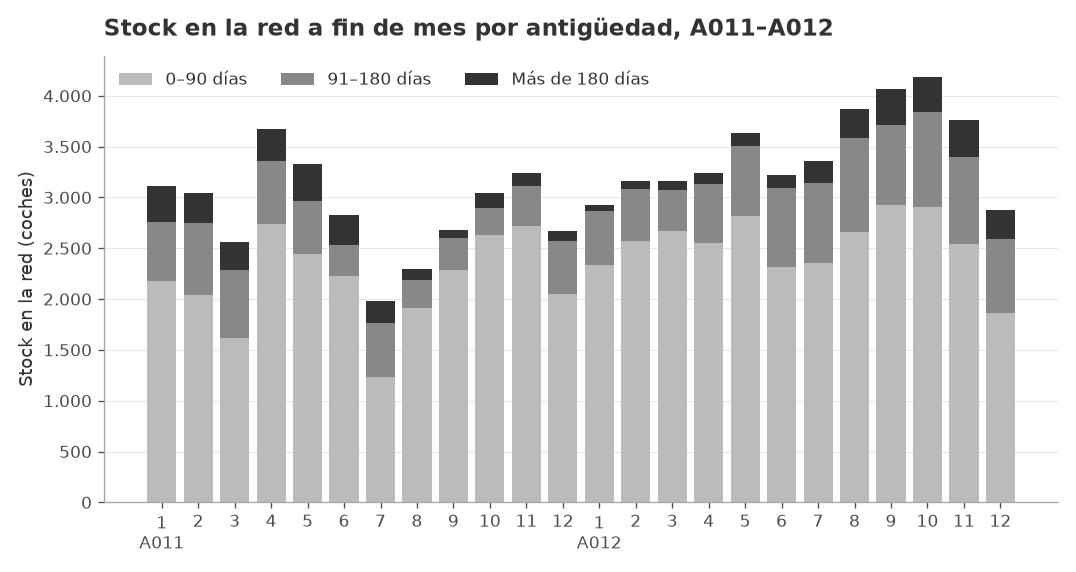

In [7]:
red = (
    dd["stock"][dd["stock"]["anio"].isin(["A011", "A012"])]
    .groupby(["t", "anio", "mes"], as_index=False)[["s_0_90", "s_91_180", "s_mas_180"]]
    .sum()
)
fig, eje = plt.subplots()
base = np.zeros(len(red))
tramos = [("s_0_90", "0–90 días", "#BBBBBB"),
          ("s_91_180", "91–180 días", GRIS_MEDIO),
          ("s_mas_180", "Más de 180 días", GRIS_OSCURO)]
for columna, etiqueta, color in tramos:
    eje.bar(red["t"], red[columna], bottom=base, color=color, label=etiqueta, width=0.8)
    base += red[columna].to_numpy()
eje.set_xticks(red["t"], [f"{m}\n{a}" if m == 1 else str(m)
                          for m, a in zip(red["mes"], red["anio"])])
eje.set_ylabel("Stock en la red (coches)")
eje.yaxis.set_major_formatter(lambda y, _: f"{y:,.0f}".replace(",", "."))
eje.set_title("Stock en la red a fin de mes por antigüedad, A011–A012")
eje.legend(ncols=3, loc="upper left")
guardar_figura(fig, "stock_red_antiguedad_a011_a012")
plt.show()

## Compras adelantadas

In [8]:
from src import datos as _datos
import numpy as np
import pandas as pd

COLUMNAS_ADELANTO = ['anio', 'segmento', 'adelanto_central', 'adelanto_min', 'adelanto_max', 'saldo_para_siguiente_anio', 'saldo_no_compensado_estimado', 'caida_compensada_estimada', 'metodo']

def _adelantos_revision(serie):
    filas = []
    economia = serie[['anio', 'mes', 'adelanto_compras', 'caida_tras_adelanto']].drop_duplicates()
    for anio, refs in [('A011', ['A009', 'A010']), ('A012', ['A009', 'A010'])]:
        eventos = economia[(economia['anio'].eq(anio)) & economia['adelanto_compras'].eq(1)]['mes'].tolist()
        caidas = economia[(economia['anio'].eq(anio)) & economia['caida_tras_adelanto'].eq(1)]['mes'].tolist()
        for seg in _datos.SEGMENTOS:
            cur = serie[(serie['anio'].eq(anio)) & serie['segmento'].eq(seg)]
            base_cur = cur[cur['mes'].lt(min(eventos) if eventos else 13)]['demanda_observada'].sum()
            obs = cur[cur['mes'].isin(eventos)]['demanda_observada'].sum()
            esperado_refs = []
            for ref in refs:
                r = serie[(serie['anio'].eq(ref)) & serie['segmento'].eq(seg) & serie['mes'].isin(eventos)]
                base_ref = serie[(serie['anio'].eq(ref)) & serie['segmento'].eq(seg) & serie['mes'].lt(min(eventos) if eventos else 13)]['demanda_observada'].sum()
                factor_ref = base_cur / base_ref if base_ref > 0 else 0.0
                esperado_refs.append(float(r['demanda_observada'].sum()) * factor_ref)
            if seg == 'CSUV' and anio == 'A012':
                mcur = cur[cur['mes'].isin(eventos)]['mercado'].sum()
                base_csuv = cur[cur['mes'].le(10)]['mercado'].sum()
                tasas_csuv = []
                for ref in refs:
                    r = serie[(serie['anio'].eq(ref)) & serie['segmento'].eq('CSUV')]
                    b = r[r['mes'].le(10)]['mercado'].sum()
                    e = r[r['mes'].isin(eventos)]['mercado'].sum()
                    if b > 0: tasas_csuv.append(e / b)
                esperado_refs = [base_csuv * tasa for tasa in tasas_csuv]
                esperado_csuv = float(np.median(esperado_refs)) if esperado_refs else mcur
                proxy_pct = np.clip((mcur - esperado_csuv) / mcur, 0, 1) if mcur > 0 else 0.0
                proxy = min(float(obs), float(obs * proxy_pct))
                lo, central, hi = 0.0, proxy / 2, proxy
                metodo = 'CSUV: porcentaje de exceso de mercado frente A009/A010; proxy limitado a ventas nov-dic'
            else:
                exceso_refs = [max(0.0, float(obs) - x) for x in esperado_refs]
                lo, hi = min(exceso_refs, default=0.0), max(exceso_refs, default=0.0)
                central = (lo + hi) / 2
                metodo = 'Exceso en meses con flag, contra A009/A010 escalados; A011 compensación separada'
            compensaciones = []
            if anio == 'A011' and caidas and central > 0:
                for ref in refs:
                    r = serie[(serie['anio'].eq(ref)) & serie['segmento'].eq(seg)]
                    obs_caida = cur[cur['mes'].isin(caidas)]['demanda_observada'].sum()
                    base_ref = r[r['mes'].lt(min(eventos))]['demanda_observada'].sum()
                    factor_ref = base_cur / base_ref if base_ref > 0 else 0.0
                    normal = r[r['mes'].isin(caidas)]['demanda_observada'].sum() * factor_ref
                    compensaciones.append(max(0.0, normal - float(obs_caida)))
            compensada = min(central, float(np.median(compensaciones)) if compensaciones else 0.0)
            saldo = max(0.0, central - compensada)
            # El saldo del episodio de agosto no identifica una transferencia a A012.
            transferencia = saldo if anio == 'A012' else np.nan
            filas.append(dict(anio=anio, segmento=seg, adelanto_central=central, adelanto_min=lo, adelanto_max=hi, saldo_para_siguiente_anio=transferencia, saldo_no_compensado_estimado=saldo, caida_compensada_estimada=compensada, metodo=metodo))
    return pd.DataFrame(filas, columns=COLUMNAS_ADELANTO)

def preparar_datos_revision():
    '''Devuelve datos, serie enriquecida, adelantos y señales alternativas de restricción.'''
    datos = _datos.cargar_datos()
    serie = _datos.serie_mensual_segmento(datos)
    adelantos = _adelantos_revision(serie)
    serie['ajuste_adelanto_mes'] = 0.0
    serie['ajuste_caida_mes'] = 0.0
    serie['demanda_subyacente'] = serie['demanda_observada'].astype(float)
    m = serie['adelanto_compras'].eq(1)
    for (anio, segmento), indices in serie[m].groupby(['anio', 'segmento']).groups.items():
        total = float(adelantos.loc[adelantos['anio'].eq(anio) & adelantos['segmento'].eq(segmento), 'adelanto_central'].iloc[0])
        pesos = serie.loc[list(indices), 'demanda_observada'].clip(lower=0).astype(float)
        if total > 0 and pesos.sum() > 0:
            descuentos = total * pesos / pesos.sum()
            serie.loc[list(indices), 'ajuste_adelanto_mes'] = descuentos
            serie.loc[list(indices), 'demanda_subyacente'] = (pesos - descuentos).clip(lower=0)
    for fila in adelantos.itertuples():
        indices = serie.index[serie['anio'].eq(fila.anio) & serie['segmento'].eq(fila.segmento) & serie['caida_tras_adelanto'].eq(1)]
        if len(indices) and fila.caida_compensada_estimada > 0:
            # Deshacer la parte estimada de caída evita contar solo el pico del episodio.
            pesos = serie.loc[indices, 'mercado'].astype(float)
            pesos = pesos / pesos.sum() if pesos.sum() else pd.Series(1 / len(indices), index=indices)
            serie.loc[indices, 'ajuste_caida_mes'] = fila.caida_compensada_estimada * pesos
    serie['demanda_subyacente'] += serie['ajuste_caida_mes']
    serie['demanda_alternativa'] = serie['demanda_observada'].astype(float)
    restricciones = serie[serie['senal_falta_stock'].eq(1)][['anio', 't', 'segmento', 'senal_falta_stock']].copy()
    restricciones['referencia_temporal'] = np.nan
    restricciones['demanda_alternativa'] = np.nan
    restricciones['aumento_estimado'] = 0.0
    for i, fila in restricciones.iterrows():
        pasado = serie[(serie['segmento'].eq(fila['segmento'])) & (serie['t'] < fila['t']) & serie['senal_falta_stock'].eq(0) & serie['adelanto_compras'].eq(0) & serie['caida_tras_adelanto'].eq(0)].tail(6)
        valido = pasado['demanda_observada'].gt(0)
        ratios = pasado.loc[valido, 'mercado'] / pasado.loc[valido, 'demanda_observada']
        ref = ratios.median() if len(ratios) else np.nan
        idx = serie.index[(serie['t'].eq(fila['t'])) & (serie['segmento'].eq(fila['segmento']))][0]
        obs, mercado = serie.loc[idx, 'demanda_observada'], serie.loc[idx, 'mercado']
        alternativa = max(obs, mercado / ref) if pd.notna(ref) and ref > 0 else obs
        restricciones.at[i, 'referencia_temporal'] = ref
        restricciones.at[i, 'demanda_alternativa'] = alternativa
        restricciones.at[i, 'aumento_estimado'] = alternativa - obs
        serie.loc[idx, 'demanda_alternativa'] = alternativa
    serie['demanda_alternativa_ajustada'] = serie['demanda_alternativa'] - serie['ajuste_adelanto_mes'] + serie['ajuste_caida_mes']
    return {'datos': datos, 'serie': serie, 'adelantos': adelantos, 'restricciones': restricciones}


## Preparación compartida para la revisión
La celda etiquetada `api` reúne imports, constantes y funciones y puede ejecutarse aislada, sin depender de resultados guardados. `preparar_datos_revision()` devuelve `datos`, `serie`, `adelantos` y `restricciones`; la serie conserva las columnas de `src.datos` y añade estimaciones sin reemplazar `demanda_observada`.

Los episodios se identifican con los flags: agosto y caída de septiembre–diciembre en A011, y noviembre–diciembre en A012. Cada referencia A009/A010 se escala por separado al nivel anterior al episodio. CSUV permanece en el total y utiliza un proxy del exceso de su mercado; un proxy cero no demuestra ausencia de adelanto. El saldo A012 alimenta una única devolución en A013.

La señal de stock bajo no demuestra ventas perdidas. `demanda_alternativa` usa solo la relación mercado/ventas observada antes del mes señalado, como referencia temporal; no sustituye las ventas observadas ni se usa como verdad para validar una previsión.

In [9]:
revision = preparar_datos_revision()
serie_revision = revision['serie']
adelantos_revision = revision['adelantos']
restricciones_revision = revision['restricciones']
assert {'anio', 't', 'segmento', 'demanda_observada', 'demanda_alternativa'} <= set(serie_revision.columns)
assert list(adelantos_revision.columns) == COLUMNAS_ADELANTO and len(adelantos_revision) == 14
guardar_tabla(serie_revision.drop(columns='fecha'), 'serie_revision_a003_a012')
guardar_tabla(adelantos_revision, 'adelantos_a011_a012')
guardar_tabla(restricciones_revision, 'restricciones_stock')
display(adelantos_revision)
display(restricciones_revision.head(12))

,anio,segmento,adelanto_central,adelanto_min,adelanto_max,saldo_para_siguiente_anio,saldo_no_compensado_estimado,caida_compensada_estimada,metodo
0,A011,B,17.444444,0.000000,34.888889,NaN,17.444444,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
1,A011,C,138.008624,121.857143,154.160105,NaN,0.000000,138.008624,"Exceso en meses con flag, contra A009/A010 esc..."
2,A011,MD,60.026122,47.365337,72.686907,NaN,17.713889,42.312233,"Exceso en meses con flag, contra A009/A010 esc..."
3,A011,SSUV,157.933674,105.236515,210.630833,NaN,157.933674,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
4,A011,CSUV,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
5,A011,MSUV,76.940224,0.000000,153.880449,NaN,0.000000,76.940224,"Exceso en meses con flag, contra A009/A010 esc..."
6,A011,S,0.000000,0.000000,0.000000,NaN,0.000000,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
7,A012,B,49.279527,32.868277,65.690778,49.279527,49.279527,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
8,A012,C,446.788810,390.471910,503.105711,446.788810,446.788810,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."
9,A012,MD,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,"Exceso en meses con flag, contra A009/A010 esc..."


,anio,t,segmento,senal_falta_stock,referencia_temporal,demanda_alternativa,aumento_estimado
110,A012,135,B,1,227.448818,120.000000,0.000000
113,A012,138,B,1,213.550868,241.000000,0.000000
118,A012,143,B,1,140.038653,200.000000,0.000000
192,A009,97,C,1,NaN,231.000000,0.000000
193,A009,98,C,1,NaN,257.000000,0.000000
194,A009,99,C,1,NaN,290.000000,0.000000
228,A012,133,C,1,66.251855,199.586866,117.586866
462,A011,127,SSUV,1,30.791897,428.521826,67.521826
463,A011,128,SSUV,1,30.791897,460.000000,0.000000
478,A012,143,SSUV,1,24.952755,532.000000,0.000000


La tabla separa magnitud central y sensibilidad metodológica; el rango no es un intervalo estadístico. En A011 se retira el exceso del pico y se restituye únicamente la caída posterior estimada y acotada por ese exceso. El saldo no compensado no identifica por sí solo compras tomadas de A012; su transferencia queda sin cuantificar.

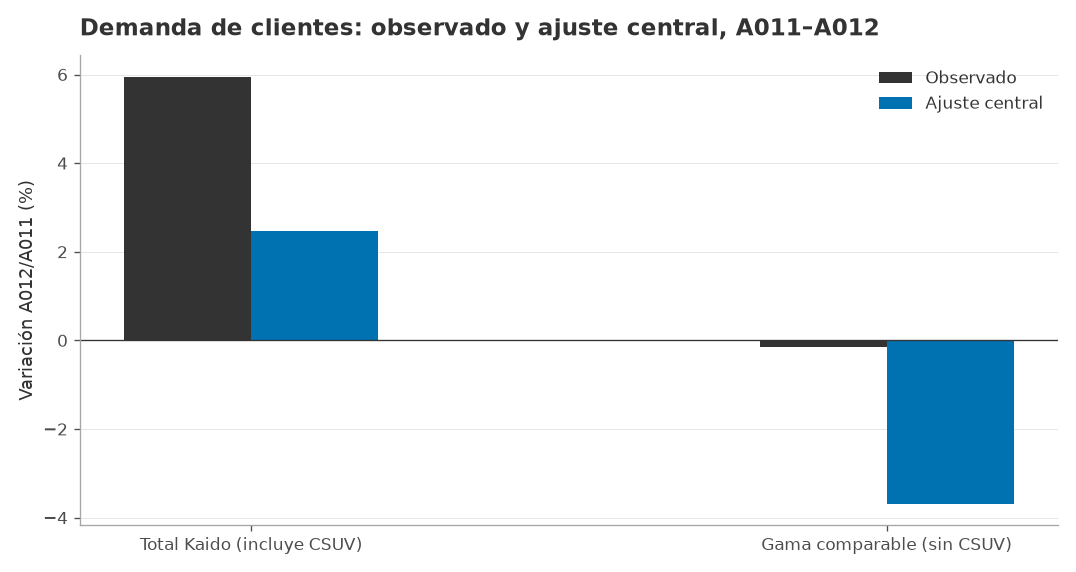

,grupo,observado_A011,observado_A012,variacion_observado_pct,ajustado_A011,ajustado_A012,variacion_ajustado_pct,alternativa_stock_A011,alternativa_stock_A012,variacion_alternativa_stock_pct
0,Total Kaido (incluye CSUV),19543,20706,0.059510,19349.907993,19827.619603,0.024688,19610.521826,20952.843677,0.068449
1,Gama comparable (sin CSUV),19543,19514,-0.001484,19349.907993,18635.619603,-0.036914,19610.521826,19760.843677,0.007665


,anio,segmento,demanda_observada,ajuste_aplicado,caida_restituida,demanda_subyacente,adelanto_central,adelanto_min,adelanto_max,saldo_para_siguiente_anio,saldo_no_compensado_estimado,caida_compensada_estimada,metodo
0,A003,B,1240,0.000000,0.0,1240.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A003,C,2542,0.000000,0.0,2542.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A003,MD,1441,0.000000,0.0,1441.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,A003,SSUV,0,0.000000,0.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,A003,CSUV,0,0.000000,0.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,A012,MD,591,0.000000,0.0,591.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
66,A012,SSUV,5635,0.000000,0.0,5635.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,"Exceso en meses con flag, contra A009/A010 esc..."
67,A012,CSUV,1192,0.000000,0.0,1192.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,CSUV: porcentaje de exceso de mercado frente A...
68,A012,MSUV,7481,361.741820,0.0,7119.258180,361.741820,0.000000,723.483640,361.741820,361.741820,0.0,"Exceso en meses con flag, contra A009/A010 esc..."


Ledger verificado: cada ajuste central se descuenta una sola vez y demanda observada permanece intacta.


In [10]:
ledger = serie_revision.groupby(['anio', 'segmento'], observed=True).agg(demanda_observada=('demanda_observada', 'sum'), ajuste_aplicado=('ajuste_adelanto_mes', 'sum'), caida_restituida=('ajuste_caida_mes', 'sum'), demanda_subyacente=('demanda_subyacente', 'sum')).reset_index()
ledger = ledger.merge(adelantos_revision, on=['anio', 'segmento'], how='left')
for _, r in ledger.iterrows(): assert abs(r['ajuste_aplicado'] - (r['adelanto_central'] if pd.notna(r['adelanto_central']) else 0.0)) < 1e-7, (r['anio'], r['segmento'])
assert np.array_equal(serie_revision['demanda_observada'].to_numpy(), serie['demanda_observada'].to_numpy())
assert (adelantos_revision['adelanto_central'] <= adelantos_revision['adelanto_max'] + 1e-9).all()
assert np.allclose(ledger['demanda_subyacente'], ledger['demanda_observada'] - ledger['ajuste_aplicado'] + ledger['caida_restituida'])
def crecimiento_por(columna, prefijo):
    anual = serie_revision[serie_revision['anio'].isin(['A011','A012'])].groupby(['anio','segmento'], observed=True)[columna].sum().unstack('anio')
    filas = []
    for grupo, segmentos in [('Total Kaido (incluye CSUV)', datos.SEGMENTOS), ('Gama comparable (sin CSUV)', [s for s in datos.SEGMENTOS if s != 'CSUV'])]:
        valores = anual.loc[segmentos].sum()
        filas.append({'grupo': grupo, f'{prefijo}_A011': valores['A011'], f'{prefijo}_A012': valores['A012'], f'variacion_{prefijo}_pct': valores['A012']/valores['A011']-1})
    return pd.DataFrame(filas)
observados = crecimiento_por('demanda_observada', 'observado')
subyacentes = crecimiento_por('demanda_subyacente', 'ajustado')
alternativa_stock = crecimiento_por('demanda_alternativa', 'alternativa_stock')
crecimiento_oficial = observados.merge(subyacentes, on='grupo').merge(alternativa_stock, on='grupo')
guardar_tabla(crecimiento_oficial, 'crecimiento_demanda_a012')
guardar_tabla(ledger, 'ledger_demanda_ajustada_a011_a012')
guardar_tabla(adelantos_revision[adelantos_revision['anio'].eq('A012')], 'exceso_adelanto_a012')
fig, ax = plt.subplots()
x = np.arange(len(crecimiento_oficial))
ancho = 0.2
for desplazamiento, columna, etiqueta, color in [(-1.5, 'variacion_observado_pct', 'Observado', '#333333'), (-0.5, 'variacion_ajustado_pct', 'Ajuste central', '#0072B2')]:
    ax.bar(x + desplazamiento * ancho, crecimiento_oficial[columna] * 100, ancho, label=etiqueta, color=color)
ax.axhline(0, color='#333333', lw=0.8)
ax.set_xticks(x - ancho, crecimiento_oficial['grupo'])
ax.set_ylabel('Variación A012/A011 (%)')
ax.set_title('Demanda de clientes: observado y ajuste central, A011–A012', loc='left')
ax.legend()
guardar_figura(fig, 'crecimiento_demanda_observado_ajustado_a012')
plt.show()
display(crecimiento_oficial)
display(ledger)
print('Ledger verificado: cada ajuste central se descuenta una sola vez y demanda observada permanece intacta.')

La tabla oficial separa el total de Kaido (incluido CSUV) de la gama comparable y presenta observado y ajustado; el ajuste no se replica en cada mes, sino que `ajuste_adelanto_mes` reparte el ledger solo entre meses con flag. Para A011 se usa el episodio marcado de agosto y se cuantifica la caída posterior observada frente a referencias escaladas; esa compensación se informa aparte y no se convierte en una transferencia cierta a A012.

Las matriculaciones observadas incluyen automatriculaciones; para medir demanda de clientes se restan del histórico. El caso base A013 programa cero automatriculaciones: es una decisión de política, no una afirmación sobre su valor histórico. Las restricciones de stock usan como alternativa solo meses anteriores sin señal, adelanto ni caída; siguen siendo una sensibilidad, no una medida de ventas perdidas observada.

In [11]:
# Los límites siguientes son alternativas de identificación, no percentiles.
filas_sensibilidad = []
adelantos_idx = adelantos_revision.set_index(["anio", "segmento"])
for grupo, segmentos in [("Total Kaido (incluye CSUV)", datos.SEGMENTOS),
                         ("Gama comparable (sin CSUV)", [s for s in datos.SEGMENTOS if s != "CSUV"])]:
    s = serie_revision[serie_revision.segmento.isin(segmentos)]
    obs = s.groupby("anio").demanda_observada.sum()
    aumentos = (s.demanda_alternativa - s.demanda_observada).groupby(s.anio).sum()
    ad11 = adelantos_idx.loc[("A011", segmentos), :]
    ad12 = adelantos_idx.loc[("A012", segmentos), :]
    for compensacion in ["ninguna", "estimada", "completa"]:
        recuperado = {"ninguna": 0.0, "estimada": ad11.caida_compensada_estimada.sum(),
                      "completa": ad11.adelanto_central.sum()}[compensacion]
        for nivel in ["min", "central", "max"]:
            for stock in [False, True]:
                a011 = obs["A011"] - ad11.adelanto_central.sum() + recuperado + (aumentos["A011"] if stock else 0)
                a012 = obs["A012"] - ad12[f"adelanto_{nivel}"].sum() + (aumentos["A012"] if stock else 0)
                filas_sensibilidad.append({"grupo": grupo, "compensacion_a011": compensacion,
                                           "adelanto_a012": nivel, "alternativa_restricciones": stock,
                                           "demanda_a011": a011, "demanda_a012": a012,
                                           "crecimiento_pct": a012 / a011 - 1})
sensibilidad_crecimiento = pd.DataFrame(filas_sensibilidad)
guardar_tabla(sensibilidad_crecimiento, "sensibilidad_crecimiento_a012")
display(sensibilidad_crecimiento.query("compensacion_a011 == 'estimada' and alternativa_restricciones == False"))
assert comprobaciones["correcto"].all()
assert (serie_revision.demanda_observada >= 0).all()
for fila in adelantos_revision.itertuples():
    episodio = serie_revision[serie_revision.anio.eq(fila.anio) & serie_revision.segmento.eq(fila.segmento) & serie_revision.adelanto_compras.eq(1)]
    assert 0 <= fila.adelanto_min <= fila.adelanto_central <= fila.adelanto_max <= episodio.demanda_observada.sum() + 1e-8
    assert np.isclose(episodio.ajuste_adelanto_mes.sum(), fila.adelanto_central)
from IPython.display import Markdown
fila_total = crecimiento_oficial.iloc[0]
fila_comparable = crecimiento_oficial.iloc[1]
display(Markdown(
    f"**Lectura de A012.** Las compras observadas de clientes crecen un "
    f"{fila_total.variacion_observado_pct:.1%}, frente a {fila_comparable.variacion_observado_pct:.1%} "
    f"en la gama comparable. El ajuste central de episodios estima {fila_total.variacion_ajustado_pct:.1%} "
    "para el total; incluye CSUV y deshace la parte estimada de caída posterior de A011. "
    "No identifica por sí solo toda la demanda potencial ni demuestra un crecimiento exacto. "
    "Los results de restricciones y compensaciones alternativas se informan por separado."))


,grupo,compensacion_a011,adelanto_a012,alternativa_restricciones,demanda_a011,demanda_a012,crecimiento_pct
6,Total Kaido (incluye CSUV),estimada,min,False,19349.907993,20275.575369,0.047838
8,Total Kaido (incluye CSUV),estimada,central,False,19349.907993,19827.619603,0.024688
10,Total Kaido (incluye CSUV),estimada,max,False,19349.907993,19379.663837,0.001538
24,Gama comparable (sin CSUV),estimada,min,False,19349.907993,19083.575369,-0.013764
26,Gama comparable (sin CSUV),estimada,central,False,19349.907993,18635.619603,-0.036914
28,Gama comparable (sin CSUV),estimada,max,False,19349.907993,18187.663837,-0.060065


**Lectura de A012.** Las compras observadas de clientes crecen un 6.0%, frente a -0.1% en la gama comparable. El ajuste central de episodios estima 2.5% para el total; incluye CSUV y deshace la parte estimada de caída posterior de A011. No identifica por sí solo toda la demanda potencial ni demuestra un crecimiento exacto. Los resultados de restricciones y compensaciones alternativas se informan por separado.

### Alcance de la estimación

Las diferencias entre referencias estacionales y las hipótesis de compensación no son un intervalo estadístico. La tabla de sensibilidad compara retirar solo el pico A011, reponer su caída estimada y suponer compensación completa, cruzado con adelantos A012 y restricciones de stock. El saldo no compensado del episodio de agosto no permite identificar una transferencia a A012.

El balance histórico se comprueba con matriculaciones, no con ventas depuradas: las discrepancias originales se conservan y cuantifican. La señal de falta de stock no mide una venta perdida; la alternativa depende de una relación pasada entre mercado y ventas. CSUV carece de historia suficiente para identificar su adelanto; la ausencia de exceso detectado por su proxy no equivale a certeza de cero.